> **หมายเหตุ:** โค้ดนี้สร้าง `target_labels` แบบ multi-label แล้ว; outputs ที่บันทึกจากการรันครั้งก่อนอาจยังเป็นผล single-label ให้รันเซลล์ใหม่ตามลำดับก่อนใช้ผล

# RakForest — EDA, Cleaning และเตรียมเสียง

โน้ตบุ๊กนี้ต่อจาก `01_download_datasets.ipynb` และดัดแปลงแนวทางจาก Colab เดิม: สำรวจ metadata/คุณภาพเสียง, ทำ label mapping, ตรวจไฟล์เสีย/เงียบ/ซ้ำ, เปรียบเทียบก่อน–หลัง cleaning และเตรียมคลิปมาตรฐานสำหรับขั้นฝึกโมเดล

ไม่ลบหรือแก้ไฟล์ดิบใน `data/raw/`; ผลลัพธ์เขียนลง `data/processed/` และรายงานลง `reports/`. FSD50K ถูกพักจาก pipeline ชั่วคราว; ชุดข้อมูลที่เปิดใช้งานต้องโหลดครบก่อนเริ่ม EDA.

## วิธีทำงานของไฟล์นี้: เตรียมข้อมูลสำหรับ multi-label

ไฟล์นี้เป็นขั้น **EDA, cleaning และเตรียม manifest ก่อนฝึกโมเดล** ป้ายจากแหล่งข้อมูลจะถูก map เป็นคลาสมาตรฐาน และเก็บป้ายทั้งหมดใน `target_labels`; `target_label` เป็นป้ายหลักที่ใช้กับกราฟ EDA และการแบ่งกลุ่มแบบเดิม

ขั้นตอนหลักคือ ตรวจคุณภาพ/ความยาว/รูปแบบไฟล์เสียง, หาไฟล์ซ้ำและรายการที่ควรตรวจทาน, แบ่ง train/validation/test ตาม recording group, แล้วเตรียมคลิป 4 วินาทีพร้อม manifest ให้ 03 ใช้ การแบ่งตาม recording ช่วยป้องกันเสียงจาก recording เดียวกันปะปนข้ามชุดข้อมูล

ป้าย metadata ของไฟล์ต้นทางถูกส่งต่อไปทุกคลิปของไฟล์นั้น จึงอาจเป็น weak label: ไม่ได้ยืนยันว่าเหตุการณ์ดังอยู่ตลอดช่วง 4 วินาที ส่วน `zenodo_fire` ยังคงเก็บไว้ตรวจใน EDA แต่ถูกพักจาก manifest สำหรับฝึกตามการตั้งค่าปัจจุบัน

หาก inventory cache ตรงกับไฟล์และ metadata จะใช้คุณสมบัติเสียงเดิมและอัปเดต mapping ปัจจุบันโดยไม่ตรวจเสียงซ้ำ; การเปลี่ยน mapping อย่างเดียวจึงไม่จำเป็นต้องสแกน waveform ใหม่ แต่การสร้าง split/manifest ยังต้องรันเซลล์ที่เกี่ยวข้องให้ครบ


## 1. ติดตั้งและ import ไลบรารี
ใช้ `tqdm` แบบมาตรฐานเพื่อหลีกเลี่ยง `IProgress not found`; progress จะแสดงเป็นข้อความแทน widget. `pyarrow` รองรับไฟล์ parquet และ `openpyxl` อ่าน metadata Excel.


In [74]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-U', 'librosa', 'datasets[audio]', 'soundfile', 'pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'tqdm', 'openpyxl', 'pyarrow'])



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


0

In [75]:
from pathlib import Path
import os, json, hashlib, warnings
from collections import Counter
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_EXTENSIONS = {'.wav', '.mp3', '.flac', '.ogg', '.m4a', '.aac'}
def existing_audio_dir(*candidates):
    for folder in candidates:
        if folder.exists() and any(p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS for p in folder.rglob('*')):
            return folder
    return candidates[0]

DATASET_DIRS = {
    'esc50': RAW_DIR/'esc50', 'footstep_set': RAW_DIR/'footstep_set',
    'datasec_v2': existing_audio_dir(RAW_DIR/'datasec_v2', RAW_DIR/'datasec_vehicle_v2'), 'rfcx_frugalai': RAW_DIR/'rfcx_frugalai',
    'fsc22': RAW_DIR/'fsc22',
    'fire_google_drive': RAW_DIR/'fire_google_drive', 'zenodo_fire': RAW_DIR/'zenodo_fire',
    'vehicle_sounds': RAW_DIR/'vehicle_sounds',
}
PAUSED_DATASETS = {'fsd50k_v1'}  # เก็บไฟล์ดิบไว้ แต่ยังไม่รวมใน EDA/model pipeline
print('Project:', PROJECT_ROOT)
print('Active datasets:', ', '.join(DATASET_DIRS))
print('Paused datasets:', ', '.join(sorted(PAUSED_DATASETS)))


Project: /Users/guidegiegg/Projects/RakForest-ML
Active datasets: esc50, footstep_set, datasec_v2, rfcx_frugalai, fsc22, fire_google_drive, zenodo_fire, vehicle_sounds
Paused datasets: fsd50k_v1


### 2.1 RFCx ที่เก็บเป็น Hugging Face Dataset
ถ้า `01_download_datasets.ipynb` บันทึก RFCx เป็น Arrow dataset cell นี้ส่งออก WAV ให้ EDA/player ใช้งาน โดยอ่าน WAV bytes ด้วย `soundfile` ตรง ๆ เพื่อเลี่ยง TorchCodec/FFmpeg mismatch; label เดิมยังคงอยู่ในชื่อโฟลเดอร์. ถ้า schema ไม่ตรงจะแสดงสาเหตุและให้ตรวจ schema ก่อน.

In [76]:
import io
RFCX_DISK_DIR=RAW_DIR/'rfcx_frugalai'/'hf_dataset'
RFCX_EXPORT_DIR=RAW_DIR/'rfcx_frugalai'/'audio_export'
RFCX_EXPORT_MARKER=RFCX_EXPORT_DIR/'.export_complete.json'
if RFCX_DISK_DIR.exists() and not RFCX_EXPORT_MARKER.exists():
    try:
        from datasets import Audio, load_from_disk
        rfcx_ds=load_from_disk(str(RFCX_DISK_DIR))
        split_items=list(rfcx_ds.items()) if hasattr(rfcx_ds,'items') else [('data',rfcx_ds)]
        RFCX_EXPORT_DIR.mkdir(parents=True,exist_ok=True)
        exported=0
        for split_name,split in split_items:
            print(f'RFCx split {split_name}: {len(split):,} rows; columns={split.column_names}')
            audio_col=next((c for c in split.column_names if c.lower() in {'audio','wav','sound'}),None)
            label_col=next((c for c in split.column_names if c.lower() in {'label','labels','class','target','category','label_id'}),None)
            if audio_col is None:
                print(f'No audio column in split {split_name}; skipping that split.'); continue
            # Read encoded WAV bytes directly. This avoids Hugging Face Audio's
            # TorchCodec decoder, which may not match the local FFmpeg libraries.
            split=split.cast_column(audio_col,Audio(decode=False))
            for idx,item in enumerate(tqdm(split,desc=f'Export RFCx {split_name}')):
                audio=item[audio_col]
                if not isinstance(audio,dict): continue
                audio_bytes=audio.get('bytes')
                audio_path=audio.get('path')
                if audio_bytes:
                    waveform,sample_rate=sf.read(io.BytesIO(audio_bytes),dtype='float32')
                elif audio_path and Path(audio_path).is_file():
                    waveform,sample_rate=sf.read(audio_path,dtype='float32')
                else:
                    continue
                label=str(item.get(label_col,'unknown')) if label_col else 'unknown'
                label=''.join(ch if ch.isalnum() or ch in '-_' else '_' for ch in label)
                out_dir=RFCX_EXPORT_DIR/label; out_dir.mkdir(parents=True,exist_ok=True)
                out=out_dir/f'{split_name}_{idx:07d}.wav'
                if not out.exists(): sf.write(out,waveform,int(sample_rate))
                exported+=1
        if exported:
            RFCX_EXPORT_MARKER.write_text(json.dumps({'exported_rows':exported,'splits':[name for name,_ in split_items]},indent=2))
            print('RFCx WAV export complete:',exported,'files at',RFCX_EXPORT_DIR)
        else:
            print('No RFCx audio was exported; inspect the dataset columns before continuing.')
    except Exception as e: print('RFCx export skipped:',type(e).__name__,str(e))
else:
    print('RFCx saved dataset not found or export is marked complete; skip export.')


RFCx saved dataset not found or export is marked complete; skip export.


### 2.2 Preflight: ตรวจว่าดาวน์โหลดครบก่อนเริ่ม
ค่าเริ่มต้นบังคับให้พบเสียงครบทั้ง 8 dataset ที่เปิดใช้งาน (พัก FSD50K ไว้) และหยุดเมื่อเจอไฟล์ดาวน์โหลดชั่วคราว เพื่อไม่ให้สร้าง manifest จากข้อมูลที่ยังมาไม่ครบ. เปลี่ยน `ALLOW_PARTIAL_DATASETS=True` ได้เฉพาะตอนต้องการทดสอบบางชุด.


In [77]:
ALLOW_PARTIAL_DATASETS=False
all_partial_downloads=[p for p in RAW_DIR.rglob('*') if p.is_file() and (p.name.endswith('.part') or p.name.endswith('.kaggle-partial'))]
# Only active dataset downloads without a complete matching archive should block EDA.
ACTIVE_DATASET_HINTS={
    'esc50':('esc50',), 'footstep_set':('footstep',), 'datasec_v2':('datasec',),
    'rfcx_frugalai':('rfcx','frugalai'), 'fsc22':('fsc22',),
    'fire_google_drive':('fire_google_drive',), 'zenodo_fire':('zenodo_fire',),
    'vehicle_sounds':('vehicle_sounds',),
}
def has_complete_archive_copy(path):
    suffix='.kaggle-partial' if path.name.endswith('.kaggle-partial') else '.part'
    complete_name=path.name[:-len(suffix)]
    return any(candidate.is_file() and candidate.name==complete_name for candidate in RAW_DIR.rglob(complete_name))
def is_active_dataset_partial(path):
    relative=path.relative_to(RAW_DIR).as_posix().lower()
    return any(hint in relative for hints in ACTIVE_DATASET_HINTS.values() for hint in hints)
partial_downloads=[p for p in all_partial_downloads if is_active_dataset_partial(p) and not has_complete_archive_copy(p)]
ignored_partial_downloads=[p for p in all_partial_downloads if p not in partial_downloads]
if ignored_partial_downloads:
    print('Ignored partial artifacts (paused/untracked datasets or a complete archive copy exists):')
    display(pd.DataFrame({'ignored_partial':[str(p) for p in ignored_partial_downloads]}))
if partial_downloads:
    display(pd.DataFrame({'incomplete_active_download':[str(p) for p in partial_downloads]}))
    if not ALLOW_PARTIAL_DATASETS:
        raise RuntimeError('พบไฟล์ดาวน์โหลดค้างของ dataset ที่เปิดใช้งานและยังไม่มี archive ฉบับสมบูรณ์; ตรวจรายการด้านบนก่อนรันต่อ หรือเปิด ALLOW_PARTIAL_DATASETS=True เพื่อใช้เฉพาะไฟล์ที่มีอยู่')
    print('[warning] กำลังทำ EDA จากไฟล์ที่มีอยู่; ไฟล์ดาวน์โหลดค้างจะไม่ถูกนำเข้า')

DATASET_AUDIO_COUNTS={name:sum(1 for p in root.rglob('*') if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS) if root.exists() else 0 for name,root in DATASET_DIRS.items()}
missing_datasets={name:count for name,count in DATASET_AUDIO_COUNTS.items() if count==0}
print('Audio file counts:',DATASET_AUDIO_COUNTS)
if missing_datasets and not ALLOW_PARTIAL_DATASETS:
    raise RuntimeError(f'ยังไม่พบไฟล์เสียงของ dataset เหล่านี้: {missing_datasets}. ให้รอ notebook 01 โหลดครบ หรือเปิด ALLOW_PARTIAL_DATASETS เพื่อทดสอบ subset ชั่วคราว')


Ignored partial artifacts (paused/untracked datasets or a complete archive copy exists):


,ignored_partial
0,/Users/guidegiegg/Projects/RakForest-ML/data/r...
1,/Users/guidegiegg/Projects/RakForest-ML/data/r...
2,/Users/guidegiegg/Projects/RakForest-ML/data/r...


Audio file counts: {'esc50': 2000, 'footstep_set': 2127, 'datasec_v2': 5048, 'rfcx_frugalai': 50397, 'fsc22': 2025, 'fire_google_drive': 721, 'zenodo_fire': 47, 'vehicle_sounds': 9448}


## 2.3 ตรวจโครงสร้างและสร้างบัญชีไฟล์เสียง
สแกนเฉพาะโฟลเดอร์ dataset ที่มีอยู่; label เบื้องต้นมาจาก metadata ที่พบ หรือชื่อโฟลเดอร์เมื่อไม่มี metadata

In [78]:
def find_metadata(root):
    if not root.exists(): return []
    return [p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv', '.tsv', '.xlsx'}]

def read_metadata_table(path):
    try:
        if path.suffix.lower()=='.xlsx': return pd.read_excel(path)
        return pd.read_csv(path, sep='\t' if path.suffix.lower()=='.tsv' else ',')
    except Exception:
        return pd.DataFrame()

def fsd50k_vocabulary(root):
    # Official FSD50K vocabulary.csv is headerless: index, class_name, AudioSet MID.
    mid_to_name={}
    for path in root.rglob('vocabulary.csv'):
        if not path.is_file(): continue
        raw=read_metadata_table(path)
        cols={str(c).strip().lower():c for c in raw.columns}
        mid_col=next((cols[k] for k in ('mid','mids','class_mid') if k in cols),None)
        name_col=next((cols[k] for k in ('label','class','name','category','display_name','class_name') if k in cols),None)
        if mid_col is not None and name_col is not None:
            rows=((mid,name) for mid,name in zip(raw[mid_col],raw[name_col]))
        else:
            raw=pd.read_csv(path,header=None)
            if raw.shape[1]<3: continue
            # Drop a header row if a nonstandard export added one.
            if str(raw.iloc[0,0]).strip().lower() in {'index','id','class_id'}:
                raw=raw.iloc[1:]
            rows=((row.iloc[2],row.iloc[1]) for _,row in raw.iterrows())
        for mid,name in rows:
            if pd.notna(mid) and pd.notna(name):
                mid_to_name[str(mid).strip()]=str(name).strip()
    return mid_to_name

def metadata_label_lookup(root, dataset):
    lookup={}
    mid_to_name=fsd50k_vocabulary(root) if dataset=='fsd50k_v1' else {}
    for meta_path in find_metadata(root):
        df=read_metadata_table(meta_path)
        if df.empty: continue
        cols={str(c).strip().lower():c for c in df.columns}
        file_col=next((cols[k] for k in ('filename','file_name','dataset file name','source file name','fname','file') if k in cols),None)
        label_col=next((cols[k] for k in ('category','class name','label','class','target','labels','mids') if k in cols),None)
        if file_col is None or label_col is None: continue
        for filename,label in zip(df[file_col],df[label_col]):
            if pd.isna(filename) or pd.isna(label): continue
            labels=[x.strip() for x in str(label).replace(';',',').split(',') if x.strip()]
            if dataset=='fsd50k_v1':
                labels=[mid_to_name.get(x,x) for x in labels]
            lookup[Path(str(filename)).stem.lower()]=' | '.join(labels)
    return lookup

WRAPPER_DIRS={'extracted','audio','wav','data','train','test','dev','eval','validation','metadata','fsc22','esc50'}
records=[]
for dataset,root in DATASET_DIRS.items():
    if not root.exists():
        print(f'[not found] {dataset}: {root}')
        continue
    lookup=metadata_label_lookup(root,dataset)
    audio=[p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS]
    print(f'{dataset}: {len(audio):,} audio files; metadata labels: {len(lookup):,}')
    for p in audio:
        rel=p.relative_to(root)
        source_label=lookup.get(p.stem.lower())
        if source_label is None:
            if dataset in {'fire_google_drive','zenodo_fire'}: source_label='fire'
            else: source_label=next((part for part in reversed(rel.parts[:-1]) if part.lower() not in WRAPPER_DIRS),'unknown')
        records.append({'dataset':dataset,'file':str(p),'relative_path':str(rel),'source_label':source_label})
files_df=pd.DataFrame(records)
if files_df.empty: raise RuntimeError('ยังไม่พบไฟล์เสียงใน data/raw; รัน download notebook ให้เสร็จก่อน')
display(files_df.groupby(['dataset','source_label']).size().rename('files').reset_index().sort_values(['dataset','files'],ascending=[True,False]).head(200))

esc50: 2,000 audio files; metadata labels: 2,000
footstep_set: 2,127 audio files; metadata labels: 0
datasec_v2: 5,048 audio files; metadata labels: 0
rfcx_frugalai: 50,397 audio files; metadata labels: 0
fsc22: 2,025 audio files; metadata labels: 2,025
fire_google_drive: 721 audio files; metadata labels: 0
zenodo_fire: 47 audio files; metadata labels: 0
vehicle_sounds: 9,448 audio files; metadata labels: 0


,dataset,source_label,files
25,datasec_v2,Voices,1900
20,datasec_v2,Music,1001
14,datasec_v2,Gunshot,141
28,datasec_v2,car pass-by,110
13,datasec_v2,Glass breaking,109
...,...,...,...
133,vehicle_sounds,Motocycles,537
132,vehicle_sounds,Helicopter,353
134,vehicle_sounds,Truck,265
131,vehicle_sounds,Cars,230


## 3. Label mapping — multi-label targets
ใช้ `target_labels` เป็นป้ายกำกับจริงสำหรับโมเดล หนึ่ง recording จึงมีได้หลายคลาสเมื่อ metadata ระบุหลายเสียง ส่วน `target_label` เก็บคลาสหลักไว้เพื่อทำ EDA และแบ่ง split แบบ group-aware ให้เข้ากับข้อมูลต้นทางเดิม; 03 จะฝึกจาก `target_labels` ไม่ใช่ `target_label`. ป้าย `silence` และ `other` ใช้เป็นแท็กเดี่ยวและไม่สร้าง synthetic mix ร่วมกับคลาสอื่น. ตรวจ `label_mapping_audit.csv` โดยเฉพาะ `other` ก่อนนำข้อมูลไปฝึก. FSD50K ยังคงพักไว้.

In [79]:
# Canonical classes: forest/fire risk events plus context classes.
TARGET_CLASSES=['fire','chainsaw','vehicle','human_activity','threat_tactical','weather','natural_ambient','silence','other']
LABEL_OVERRIDES={
 'esc50':{
  'crackling_fire':'fire','chainsaw':'chainsaw','engine':'vehicle','car_horn':'vehicle','siren':'vehicle','airplane':'vehicle','helicopter':'vehicle','train':'vehicle',
  'footsteps':'human_activity','laughing':'human_activity','coughing':'human_activity','clapping':'human_activity','crying_baby':'human_activity','breathing':'human_activity',
  'fireworks':'threat_tactical','hand_saw':'threat_tactical','rain':'weather','thunderstorm':'weather','wind':'weather','sea_waves':'weather',
  'chirping_birds':'natural_ambient','crickets':'natural_ambient','insects':'natural_ambient','frog':'natural_ambient','dog':'natural_ambient','cat':'natural_ambient'},
 'fsc22':{
  'fire':'fire','chainsaw':'chainsaw','vehicleengine':'vehicle','generator':'vehicle','helicopter':'vehicle','footsteps':'human_activity','speaking':'human_activity','clapping':'human_activity','whistling':'human_activity',
  'gunshot':'threat_tactical','axe':'threat_tactical','handsaw':'threat_tactical','woodchop':'threat_tactical','treefalling':'threat_tactical','firework':'threat_tactical',
  'rain':'weather','thunderstorm':'weather','wind':'weather','waterdrops':'weather','birdchirping':'natural_ambient','frog':'natural_ambient','insect':'natural_ambient','lion':'natural_ambient','squirrel':'natural_ambient','wolfhowl':'natural_ambient','silence':'silence'},
 'rfcx_frugalai':{'0':'chainsaw','chainsaw':'chainsaw','1':'natural_ambient','environment':'natural_ambient'},
 'footstep_set':{},
 'datasec_v2':{},
 'fsd50k_v1':{},
 'vehicle_sounds':{},
 'fire_google_drive':{},'zenodo_fire':{},
}

def normalize_key(value): return ''.join(ch for ch in str(value).lower() if ch.isalnum())

def map_one_source_label(value):
    key=normalize_key(value)
    if not key: return 'other'
    if any(k in key for k in ('cracklingfire','fire','wildfire','burning','flame')): return 'fire'
    if any(k in key for k in ('chainsaw','chain saw','logging')): return 'chainsaw'
    if any(k in key for k in ('vehicle','engine','motor','car','truck','bus','motorcycle','airplane','helicopter','train','horn')): return 'vehicle'
    if any(k in key for k in ('human','person','speech','speaking','voice','footstep','walking','clap','whistle','conversation','scream','laugh','cough')): return 'human_activity'
    if any(k in key for k in ('gunshot','axe','handsaw','woodsaw','treefall','firework','explosion','poaching')): return 'threat_tactical'
    if any(k in key for k in ('rain','wind','thunder','storm','weather','waterdrop')): return 'weather'
    if any(k in key for k in ('bird','animal','insect','frog','forest','ambient','environment','wildlife')): return 'natural_ambient'
    if 'silence' in key: return 'silence'
    return 'other'

def map_labels(row):
    # These collections are intentionally single-source labels until segment annotations say otherwise.
    if row['dataset']=='footstep_set': return ['human_activity']
    if row['dataset'] in {'fire_google_drive','zenodo_fire'}: return ['fire']
    if row['dataset']=='vehicle_sounds': return ['vehicle']
    raw=str(row['source_label']).strip()
    overrides=LABEL_OVERRIDES.get(row['dataset'],{})
    direct={normalize_key(k):v for k,v in overrides.items()}
    # Preserve every distinct mapped tag from multi-label metadata rather than selecting one winner.
    parts=[x.strip() for x in __import__('re').split(r'[|;,]',raw) if x.strip()]
    mapped=[]
    for part in parts:
        target=direct.get(normalize_key(part),map_one_source_label(part))
        if target not in mapped: mapped.append(target)
    if len(mapped)>1: mapped=[target for target in mapped if target not in {'silence','other'}]
    return [target for target in TARGET_CLASSES if target in mapped] or ['other']

def map_label(row):
    # Primary tag is retained only for legacy single-label EDA and group stratification.
    return map_labels(row)[0]

files_df['target_label']=files_df.apply(map_label,axis=1)
files_df['target_labels']=files_df.apply(lambda row:json.dumps(map_labels(row),ensure_ascii=False),axis=1)
label_audit=files_df.groupby(['dataset','source_label','target_label','target_labels']).size().rename('files').reset_index()
display(label_audit.sort_values(['dataset','target_label','files'],ascending=[True,True,False]))
label_audit.to_csv(REPORT_DIR/'label_mapping_audit.csv',index=False)

print('FSD50K is paused and excluded from this label audit.')


,dataset,source_label,target_label,target_labels,files
12,datasec_v2,Fireworks,fire,"[""fire""]",68
25,datasec_v2,Voices,human_activity,"[""human_activity""]",1900
3,datasec_v2,Birds,natural_ambient,"[""natural_ambient""]",69
20,datasec_v2,Music,other,"[""other""]",1001
13,datasec_v2,Glass breaking,other,"[""other""]",109
...,...,...,...,...,...
133,vehicle_sounds,Motocycles,vehicle,"[""vehicle""]",537
132,vehicle_sounds,Helicopter,vehicle,"[""vehicle""]",353
134,vehicle_sounds,Truck,vehicle,"[""vehicle""]",265
131,vehicle_sounds,Cars,vehicle,"[""vehicle""]",230


FSD50K is paused and excluded from this label audit.


### 3.1 Provenance audit
ตรวจชื่อไฟล์ซ้ำข้ามแหล่งและ label ที่ map เป็น `other`; รายการเหล่านี้ต้องตรวจจาก metadata/เสียงจริงก่อนทำชุดฝึก.

In [80]:
# File-stem overlap is only a provenance clue, not proof of duplicate audio.
stem_audit=files_df.assign(stem=files_df.file.map(lambda p:Path(p).stem.lower()))
stem_counts=stem_audit.groupby('stem').agg(dataset_count=('dataset','nunique'),datasets=('dataset',lambda x:', '.join(sorted(set(x)))),file_count=('file','size')).reset_index()
provenance_candidates=stem_audit.merge(stem_counts[stem_counts.dataset_count>1],on='stem',suffixes=('','_audit'))
print('Filename stems shared across datasets:',provenance_candidates.stem.nunique())
display(provenance_candidates[['stem','dataset','source_label','target_label','target_labels','datasets','file_count']].head(100))
display(label_audit[label_audit.target_label.eq('other')].sort_values('files',ascending=False).head(100))
provenance_candidates.to_csv(REPORT_DIR/'provenance_candidates.csv',index=False)


Filename stems shared across datasets: 0


,stem,dataset,source_label,target_label,target_labels,datasets,file_count


,dataset,source_label,target_label,target_labels,files
20,datasec_v2,Music,other,"[""other""]",1001
13,datasec_v2,Glass breaking,other,"[""other""]",109
17,datasec_v2,Jet aircrafts,other,"[""other""]",103
4,datasec_v2,Brush cutter,other,"[""other""]",86
124,fsc22,WingFlaping,other,"[""other""]",75
11,datasec_v2,Dog barkings and howlings,other,"[""other""]",70
23,datasec_v2,Sirens,other,"[""other""]",68
2,datasec_v2,Bells,other,"[""other""]",67
10,datasec_v2,DATASEC,other,"[""other""]",67
34,datasec_v2,jackhammer,other,"[""other""]",63


## 4. EDA: class balance และ technical consistency
อ่าน header ก่อนเพื่อเก็บ sample rate/channel/duration; waveform features คำนวณจากเสียงที่อ่านได้

In [81]:
def inspect_audio(path):
    row={'duration':np.nan,'sample_rate':np.nan,'channels':np.nan,'frames':np.nan,'rms':np.nan,'peak':np.nan,'clipping_ratio':np.nan,'spectral_centroid':np.nan,'zcr':np.nan,'read_error':None}
    try:
        info=sf.info(path); row.update(duration=info.duration,sample_rate=info.samplerate,channels=info.channels,frames=info.frames)
        y,sr=librosa.load(path,sr=None,mono=True)
        if len(y):
            row['rms']=float(np.sqrt(np.mean(y.astype(np.float64)**2)))
            row['peak']=float(np.max(np.abs(y)))
            row['clipping_ratio']=float(np.mean(np.abs(y)>=0.99))
            row['spectral_centroid']=float(np.mean(librosa.feature.spectral_centroid(y=y,sr=sr)))
            row['zcr']=float(np.mean(librosa.feature.zero_crossing_rate(y)))
    except Exception as e: row['read_error']=f'{type(e).__name__}: {e}'
    return row

inventory_path=REPORT_DIR/'audio_inventory.parquet'
cache_key_cols=['dataset','file','relative_path','source_label']
metric_cols=['duration','sample_rate','channels','frames','rms','peak','clipping_ratio','spectral_centroid','zcr','read_error']
cache_reused=False
if inventory_path.exists():
    try:
        cached_inventory=pd.read_parquet(inventory_path)
        cache_matches=all(col in cached_inventory.columns for col in cache_key_cols+metric_cols)
        if cache_matches and len(cached_inventory)==len(files_df):
            current_keys=files_df[cache_key_cols].astype('string').sort_values(['dataset','file']).reset_index(drop=True)
            cached_keys=cached_inventory[cache_key_cols].astype('string').sort_values(['dataset','file']).reset_index(drop=True)
            cache_matches=current_keys.equals(cached_keys)
        else:
            cache_matches=False
        if cache_matches:
            all_df=cached_inventory.copy()
            # Mapping rules can change without changing the audio. Refresh labels from the current mapping
            # while reusing measured audio features, so edits to multi-label mapping do not trigger a rescan.
            current_labels=files_df.set_index('file')[['target_label','target_labels']]
            all_df['target_label']=all_df['file'].map(current_labels['target_label'])
            all_df['target_labels']=all_df['file'].map(current_labels['target_labels'])
            cache_reused=True
            print(f'[cache] Reused audio inventory: {len(all_df):,} files; refreshed current labels without re-inspecting audio.')
        else:
            print('[cache] Inventory does not match the current file/label list; inspecting audio again.')
    except Exception as e:
        print(f'[cache] Could not read existing inventory ({type(e).__name__}: {e}); inspecting audio again.')
if not cache_reused:
    quality=[]
    for row in tqdm(files_df.itertuples(index=False),total=len(files_df),desc='Inspect audio'):
        quality.append(inspect_audio(row.file))
    all_df=pd.concat([files_df.reset_index(drop=True),pd.DataFrame(quality)],axis=1)
    all_df.to_parquet(inventory_path,index=False)
    print('Saved audio inventory:',inventory_path)
print('Audio files:',len(all_df),' | unreadable:',all_df.read_error.notna().sum())
display(all_df.groupby('dataset').agg(files=('file','count'),duration_hours=('duration',lambda s:s.sum()/3600),sample_rates=('sample_rate',lambda s:', '.join(map(str,sorted(s.dropna().astype(int).unique())))),channels=('channels',lambda s:', '.join(map(str,sorted(s.dropna().astype(int).unique())))),errors=('read_error','count')).reset_index())


[cache] Reused audio inventory: 71,813 files; refreshed current labels without re-inspecting audio.
Audio files: 71813  | unreadable: 0


,dataset,files,duration_hours,sample_rates,channels,errors
0,datasec_v2,5048,23.709844,44100,1,0
1,esc50,2000,2.777778,44100,1,0
2,fire_google_drive,721,1.000935,48000,2,0
3,footstep_set,2127,2.402712,44100,1,0
4,fsc22,2025,2.812500,"8000, 11025, 16000, 22050, 24000, 32000, 44000...","1, 2, 8",0
5,rfcx_frugalai,50397,41.831995,"12000, 24000",1,0
6,vehicle_sounds,9448,13.118713,"44100, 48000","1, 2",0
7,zenodo_fire,47,8.503900,96000,"1, 2",0


### 4.1 Dataset overview
สรุปแหล่งข้อมูลและไฟล์ที่ตรวจพบจริง; จำนวนอ้างอิงเป็นข้อมูลเอกสารโดยประมาณ ต้องตรวจสอบกับ record/metadata ก่อนอ้างในรายงาน. License ของแต่ละแหล่งควรตรวจเงื่อนไขต้นทางก่อนเผยแพร่หรือใช้เชิงพาณิชย์.

In [82]:
DATASET_SOURCES={
 'esc50':('ESC-50','https://github.com/karolpiczak/ESC-50','2,000 clips / 50 classes','Review source license'),
 'footstep_set':('Footstep-set','https://zenodo.org/records/14286414','2,127 footstep clips / 9 classes','Review Zenodo license'),
 'datasec_v2':('DataSEC v2','https://zenodo.org/records/15393250','5,051 WAV / 22 classes','Review Zenodo license'),
 'rfcx_frugalai':('RFCx FrugalAI','https://huggingface.co/datasets/rfcx/frugalai','Chainsaw / environment','Gated access; review license/terms'),
 'fsc22':('FSC22','https://www.kaggle.com/datasets/irmiot22/fsc22-dataset','2,025 clips / 27 classes','Review Kaggle/source license'),
 'fsd50k_v1':('FSD50K v1.0 (paused)','https://zenodo.org/records/4060432','51,197 clips / 200 classes','Paused; excluded from EDA/model pipeline'),
 'fire_google_drive':('Google Drive Fire Sounds','https://drive.google.com/drive/folders/1QOYouznSh3YZR_6tbDPDQIHNyLorzqXN','Count from accessible folder','Confirm owner terms'),
 'zenodo_fire':('Zenodo Fire','https://zenodo.org/records/20132520','Count from record files','Review Zenodo license'),
 'vehicle_sounds':('Vehicle Sounds Dataset','https://www.kaggle.com/datasets/janboubiabderrahim/vehicle-sounds-dataset','Count from downloaded files','Review Kaggle/source license'),
}
actual=all_df.groupby('dataset').agg(actual_audio_files=('file','nunique'),readable=('read_error',lambda x:int(x.isna().sum())),duration_hours=('duration',lambda x:round(x.sum()/3600,2)),source_classes=('source_label','nunique')).reset_index()
overview=pd.DataFrame([{'dataset':k,'name':v[0],'source':v[1],'reference_size/classes':v[2],'license_note':v[3]} for k,v in DATASET_SOURCES.items()]).merge(actual,on='dataset',how='left')
overview['pipeline_status']=overview.dataset.map(lambda name:'paused' if name in PAUSED_DATASETS else 'active')
overview.loc[overview.pipeline_status.eq('paused'),['actual_audio_files','readable','duration_hours','source_classes']]=np.nan
display(overview)
overview.to_csv(REPORT_DIR/'dataset_overview.csv',index=False)


,dataset,name,source,reference_size/classes,license_note,actual_audio_files,readable,duration_hours,source_classes,pipeline_status
0,esc50,ESC-50,https://github.com/karolpiczak/ESC-50,"2,000 clips / 50 classes",Review source license,2000.0,2000.0,2.78,50.0,active
1,footstep_set,Footstep-set,https://zenodo.org/records/14286414,"2,127 footstep clips / 9 classes",Review Zenodo license,2127.0,2127.0,2.40,9.0,active
2,datasec_v2,DataSEC v2,https://zenodo.org/records/15393250,"5,051 WAV / 22 classes",Review Zenodo license,5048.0,5048.0,23.71,40.0,active
3,rfcx_frugalai,RFCx FrugalAI,https://huggingface.co/datasets/rfcx/frugalai,Chainsaw / environment,Gated access; review license/terms,50397.0,50397.0,41.83,2.0,active
4,fsc22,FSC22,https://www.kaggle.com/datasets/irmiot22/fsc22...,"2,025 clips / 27 classes",Review Kaggle/source license,2025.0,2025.0,2.81,27.0,active
5,fsd50k_v1,FSD50K v1.0 (paused),https://zenodo.org/records/4060432,"51,197 clips / 200 classes",Paused; excluded from EDA/model pipeline,NaN,NaN,NaN,NaN,paused
6,fire_google_drive,Google Drive Fire Sounds,https://drive.google.com/drive/folders/1QOYouz...,Count from accessible folder,Confirm owner terms,721.0,721.0,1.00,1.0,active
7,zenodo_fire,Zenodo Fire,https://zenodo.org/records/20132520,Count from record files,Review Zenodo license,47.0,47.0,8.50,1.0,active
8,vehicle_sounds,Vehicle Sounds Dataset,https://www.kaggle.com/datasets/janboubiabderr...,Count from downloaded files,Review Kaggle/source license,9448.0,9448.0,13.12,8.0,active


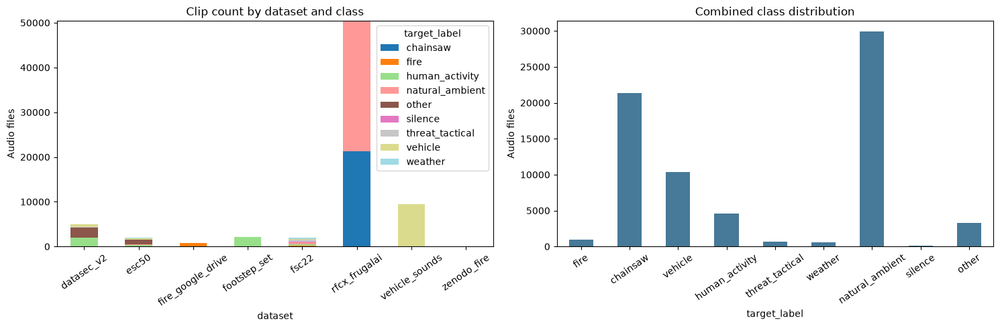

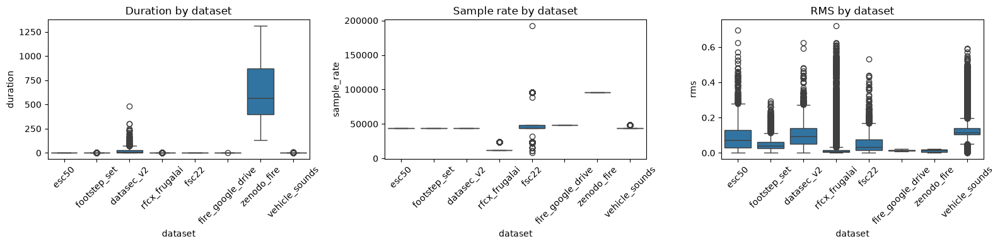

In [83]:
fig,axes=plt.subplots(1,2,figsize=(15,5))
counts=pd.crosstab(all_df['dataset'],all_df['target_label'])
counts.plot(kind='bar',stacked=True,ax=axes[0],colormap='tab20')
axes[0].set_title('Clip count by dataset and class'); axes[0].set_ylabel('Audio files'); axes[0].tick_params(axis='x',rotation=35)
class_counts=all_df['target_label'].value_counts().reindex(TARGET_CLASSES).dropna()
class_counts.plot(kind='bar',ax=axes[1],color='#477998')
axes[1].set_title('Combined class distribution'); axes[1].set_ylabel('Audio files'); axes[1].tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,3,figsize=(16,4))
sns.boxplot(data=all_df,x='dataset',y='duration',ax=axes[0]); axes[0].set_title('Duration by dataset')
sns.boxplot(data=all_df,x='dataset',y='sample_rate',ax=axes[1]); axes[1].set_title('Sample rate by dataset')
sns.boxplot(data=all_df,x='dataset',y='rms',ax=axes[2]); axes[2].set_title('RMS by dataset')
for ax in axes: ax.tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()


### 4.2 Missing data check
ตรวจช่องว่างในฟีเจอร์/metadata ก่อน cleaning และแจ้งจำนวนแถวที่เสียงอ่านไม่สำเร็จ.

In [84]:
missing=(all_df.isna().sum().rename('missing_count').to_frame())
missing['missing_pct']=(missing['missing_count']/max(len(all_df),1)*100).round(2)
display(missing.sort_values('missing_count',ascending=False))
print('Unreadable audio:',int(all_df.read_error.notna().sum()),'of',len(all_df))


,missing_count,missing_pct
read_error,71813,100.00
rms,5,0.01
peak,5,0.01
clipping_ratio,5,0.01
spectral_centroid,5,0.01
zcr,5,0.01
dataset,0,0.00
file,0,0.00
relative_path,0,0.00
source_label,0,0.00


Unreadable audio: 0 of 71813


### 4.3 Feature distributions and outlier review
แสดง RMS, spectral centroid, ZCR แยกคลาส และสรุป IQR flags แยก dataset/class. Outlier เก็บไว้จนกว่าจะฟังหรือพบหลักฐานว่าเป็นไฟล์เสีย.

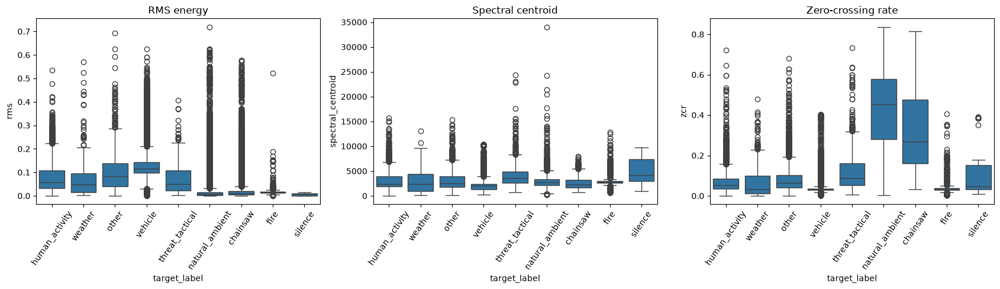

In [85]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,col,title in zip(axes,['rms','spectral_centroid','zcr'],['RMS energy','Spectral centroid','Zero-crossing rate']):
    sns.boxplot(data=all_df,x='target_label',y=col,ax=ax)
    ax.set_title(title); ax.tick_params(axis='x',rotation=55)
plt.tight_layout(); plt.show()


## 5. Cleaning audit: read errors, silence, clipping, outliers, exact duplicates
แนวเดียวกับ Colab: IQR outlier แยกตาม target class เป็นเพียงธงให้ตรวจ; silence RMS < 1e-4 และ clipping ratio > 1% เป็น flags; exact hash แยก duplicate label conflicts. ไม่ลบ raw อัตโนมัติ.


In [86]:
SILENCE_RMS_THRESHOLD=1e-4
CLIPPING_RATIO_FLAG=0.001
all_df['is_silent']=all_df['rms'].lt(SILENCE_RMS_THRESHOLD)
all_df['clipping_flag']=all_df['clipping_ratio'].gt(CLIPPING_RATIO_FLAG)
# SHA-256 exact duplicate audit; retain the first path per hash, preferring dataset ordering above.
def sha256_file(path,chunk=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(chunk),b''): h.update(block)
    return h.hexdigest()
hashes=[]
for path in tqdm(all_df['file'],desc='Hash exact duplicates'):
    try: hashes.append(sha256_file(path))
    except Exception: hashes.append(None)
all_df['sha256']=hashes
all_df['duplicate_exact']=all_df['sha256'].notna() & all_df.duplicated('sha256',keep='first')
all_df['clean_reason']='keep'
all_df.loc[all_df.read_error.notna(),'clean_reason']='unreadable'
all_df.loc[all_df.is_silent & all_df.target_label.ne('silence') & all_df.clean_reason.eq('keep'),'clean_reason']='near_silent'
# Exact duplicate audio with conflicting multi-label targets is excluded as a whole group for review.
label_counts=all_df[all_df.sha256.notna()].groupby('sha256')['target_labels'].nunique()
conflict_hashes=set(label_counts[label_counts>1].index)
all_df['duplicate_label_conflict']=all_df.sha256.isin(conflict_hashes)
all_df.loc[all_df.duplicate_label_conflict & all_df.clean_reason.eq('keep'),'clean_reason']='duplicate_label_conflict'
all_df.loc[all_df.duplicate_exact & ~all_df.duplicate_label_conflict & all_df.clean_reason.eq('keep'),'clean_reason']='exact_duplicate'
# Add class-wise IQR flags for review only; never auto-delete statistical outliers.
for col in ('duration','rms','spectral_centroid','zcr'):
    grouped=all_df.groupby('target_label')[col]
    q1=grouped.transform(lambda values:values.quantile(.25))
    q3=grouped.transform(lambda values:values.quantile(.75))
    n=grouped.transform('count')
    iqr=q3-q1
    all_df[f'outlier_{col}']=((all_df[col]<q1-1.5*iqr)|(all_df[col]>q3+1.5*iqr)) & n.ge(4)
all_df['outlier_any']=all_df[[f'outlier_{c}' for c in ('duration','rms','spectral_centroid','zcr')]].any(axis=1)
outlier_cols=[c for c in all_df.columns if c.startswith('outlier_') and c!='outlier_any']
outlier_summary=all_df.groupby(['dataset','target_label'])[outlier_cols+['outlier_any']].sum().reset_index()
display(outlier_summary)
all_df['keep_for_cleaning']=all_df['clean_reason'].eq('keep')
print(all_df['clean_reason'].value_counts(dropna=False))
print('Clipping flagged (review, not auto-removed):',int(all_df['clipping_flag'].sum()))
display(all_df.groupby(['dataset','clean_reason']).size().rename('files').reset_index())
all_df.to_parquet(REPORT_DIR/'cleaning_audit.parquet',index=False)
all_df[~all_df.keep_for_cleaning].to_csv(REPORT_DIR/'excluded_files_review.csv',index=False)


Hash exact duplicates: 100%|██████████| 71813/71813 [00:47<00:00, 1514.88it/s]


,dataset,target_label,outlier_duration,outlier_rms,outlier_spectral_centroid,outlier_zcr,outlier_any
0,datasec_v2,fire,67,32,59,50,68
1,datasec_v2,human_activity,401,124,0,3,494
2,datasec_v2,natural_ambient,69,29,19,0,69
3,datasec_v2,other,52,20,58,253,314
4,datasec_v2,threat_tactical,141,6,0,0,141
5,datasec_v2,vehicle,488,100,31,283,491
6,datasec_v2,weather,126,2,0,0,126
7,esc50,chainsaw,40,39,4,0,40
8,esc50,fire,0,22,35,28,40
9,esc50,human_activity,0,7,1,12,19


clean_reason
keep                        71649
duplicate_label_conflict      108
exact_duplicate                51
near_silent                     5
Name: count, dtype: int64
Clipping flagged (review, not auto-removed): 1119


,dataset,clean_reason,files
0,datasec_v2,duplicate_label_conflict,54
1,datasec_v2,exact_duplicate,42
2,datasec_v2,keep,4952
3,esc50,duplicate_label_conflict,54
4,esc50,keep,1946
5,fire_google_drive,keep,721
6,footstep_set,exact_duplicate,5
7,footstep_set,keep,2117
8,footstep_set,near_silent,5
9,fsc22,exact_duplicate,1


## 6. ฟังและตรวจไฟล์ซ้ำ/เสียงคล้ายและ outlier
ใช้ audio player ของ Jupyter เปิดฟังไฟล์จริงได้. คู่เสียงคล้ายเป็น candidate จากคุณสมบัติพื้นฐาน (duration, RMS, spectral centroid, ZCR) เท่านั้น จึงต้องฟังยืนยันเอง; ระบบไม่ลบ raw files. หลังตรวจสามารถเลือกแถวใน audit แล้วบันทึก exclusion list เพื่อนำไปใช้กับ manifest.

In [87]:
from IPython.display import Audio, display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

def play_file(path, rate=None):
    path=Path(path)
    if not path.is_file():
        print('ไม่พบไฟล์:',path); return
    y,sr=librosa.load(path,sr=rate,mono=True)
    display(Markdown(f'**{path.name}** — {sr:,} Hz, {len(y)/sr:.2f} s'))
    display(Audio(y,rate=sr))

# เลือก dataset/label แล้วฟังตัวอย่างจากตาราง inventory
PREVIEW_DATASET = files_df['dataset'].iloc[0]
PREVIEW_LABEL = None  # ใส่ค่าเช่น 'footsteps' หรือ None เพื่อไม่กรอง label
preview=all_df[all_df.dataset.eq(PREVIEW_DATASET)]
if PREVIEW_LABEL is not None: preview=preview[preview.source_label.eq(PREVIEW_LABEL)]
print(f'{len(preview)} files available; showing up to 5 audio players')
for row in preview.head(5).itertuples(): play_file(row.file)


2000 files available; showing up to 5 audio players


**1-104089-A-22.wav** — 44,100 Hz, 5.00 s

**3-246513-B-16.wav** — 44,100 Hz, 5.00 s

**1-96950-B-9.wav** — 44,100 Hz, 5.00 s

**2-105270-A-47.wav** — 44,100 Hz, 5.00 s

**4-90014-B-42.wav** — 44,100 Hz, 5.00 s

### FSD50K ถูกพักไว้ชั่วคราว

ข้อมูล FSD50K ยังเก็บอยู่ใน `data/raw/` แต่ไม่ถูกรวมใน inventory, label audit หรือขั้นเตรียมข้อมูลสำหรับโมเดล หากต้องการนำกลับมาใช้ภายหลัง ให้เพิ่ม `fsd50k_v1` ใน `DATASET_DIRS` แล้วเปิดการตรวจ mapping อีกครั้ง.

### 6.1 Removal audit และฟังไฟล์ที่ติดธง
แสดงรายการที่อาจถูกตัดออก พร้อม player ฟังตัวอย่าง และเปิดฟัง outlier ทางสถิติ. การตัดสินใจสุดท้ายทำใน `MANUAL_EXCLUDE_FILES`; ไม่มีการลบไฟล์จาก disk.


In [88]:
removal_review=all_df[~all_df.keep_for_cleaning].copy()
print('Removal candidates by reason:')
display(removal_review.groupby(['clean_reason','dataset']).size().rename('files').reset_index())
for reason in removal_review.clean_reason.unique():
    group=removal_review[removal_review.clean_reason.eq(reason)].head(3)
    display(Markdown(f'#### {reason} — sample playback'))
    for row in group.itertuples(): print(row.dataset,row.source_label,Path(row.file).name); play_file(row.file)

# IQR flags only: preview up to two per metric, keeping them unless listening confirms corruption.
for col in [x for x in all_df.columns if x.startswith('outlier_') and x!='outlier_any']:
    flagged=all_df[all_df[col].fillna(False)].head(2)
    print(f'{col}: {int(all_df[col].sum())} flagged; previewing {len(flagged)}')
    for row in flagged.itertuples(): print(row.dataset,row.target_label,Path(row.file).name); play_file(row.file)


Removal candidates by reason:


,clean_reason,dataset,files
0,duplicate_label_conflict,datasec_v2,54
1,duplicate_label_conflict,esc50,54
2,exact_duplicate,datasec_v2,42
3,exact_duplicate,footstep_set,5
4,exact_duplicate,fsc22,1
5,exact_duplicate,rfcx_frugalai,3
6,near_silent,footstep_set,5


#### duplicate_label_conflict — sample playback

esc50 siren 4-90014-B-42.wav


**4-90014-B-42.wav** — 44,100 Hz, 5.00 s

esc50 crickets 3-129678-A-13.wav


... (30 outputs left out)

outlier_zcr: 3511 flagged; previewing 2
esc50 vehicle 2-105270-A-47.wav


**2-105270-A-47.wav** — 44,100 Hz, 5.00 s

esc50 vehicle 4-90014-B-42.wav


**4-90014-B-42.wav** — 44,100 Hz, 5.00 s

In [89]:
# Compute comparison features on decimated set if corpus is very large.
SIMILARITY_MAX_FILES=12000
SIMILARITY_FEATURES=['duration','rms','spectral_centroid','zcr']
feature_rows=[]
feature_source=all_df[all_df.read_error.isna()].copy()
if len(feature_source)>SIMILARITY_MAX_FILES:
    print(f'Large corpus: sampling {SIMILARITY_MAX_FILES:,} recordings for near-duplicate candidates')
    feature_source=feature_source.sample(SIMILARITY_MAX_FILES,random_state=42)
for row in tqdm(feature_source.itertuples(),total=len(feature_source),desc='Audio similarity features'):
    try:
        y,sr=librosa.load(row.file,sr=16000,mono=True,duration=30)
        if len(y)<512: continue
        feature_rows.append({'row_id':row.Index,'file':row.file,'dataset':row.dataset,'source_label':row.source_label,'target_label':row.target_label,
            'duration':row.duration,'rms':float(np.sqrt(np.mean(y.astype(np.float64)**2))),
            'spectral_centroid':float(np.mean(librosa.feature.spectral_centroid(y=y,sr=16000))),
            'zcr':float(np.mean(librosa.feature.zero_crossing_rate(y)))})
    except Exception: pass
sim_df=pd.DataFrame(feature_rows)
if len(sim_df)>1:
    X=StandardScaler().fit_transform(sim_df[SIMILARITY_FEATURES].replace([np.inf,-np.inf],np.nan).fillna(0))
    k=min(6,len(sim_df))
    distances,indices=NearestNeighbors(n_neighbors=k,metric='euclidean').fit(X).kneighbors(X)
    pairs=[]
    for i in range(len(sim_df)):
        for dist,j in zip(distances[i],indices[i]):
            if j<=i: continue
            a,b=sim_df.iloc[i],sim_df.iloc[j]
            pairs.append({'file_a':a.file,'dataset_a':a.dataset,'label_a':a.source_label,'file_b':b.file,'dataset_b':b.dataset,'label_b':b.source_label,'feature_distance':float(dist),'same_label':a.target_label==b.target_label})
    candidate_pairs=pd.DataFrame(pairs).drop_duplicates(subset=['file_a','file_b']).sort_values('feature_distance').reset_index(drop=True)
    candidate_pairs.to_csv(REPORT_DIR/'near_duplicate_candidates.csv',index=False)
    display(candidate_pairs.head(30))
else:
    candidate_pairs=pd.DataFrame(); print('ต้องมีไฟล์ที่อ่านได้อย่างน้อย 2 ไฟล์')


Large corpus: sampling 12,000 recordings for near-duplicate candidates


Audio similarity features: 100%|██████████| 12000/12000 [01:09<00:00, 173.06it/s]


,file_a,dataset_a,label_a,file_b,dataset_b,label_b,feature_distance,same_label
0,/Users/guidegiegg/Projects/RakForest-ML/data/r...,esc50,crickets,/Users/guidegiegg/Projects/RakForest-ML/data/r...,datasec_v2,Cicadas,0.000000,False
1,/Users/guidegiegg/Projects/RakForest-ML/data/r...,footstep_set,wood,/Users/guidegiegg/Projects/RakForest-ML/data/r...,footstep_set,wood,0.000000,True
2,/Users/guidegiegg/Projects/RakForest-ML/data/r...,esc50,siren,/Users/guidegiegg/Projects/RakForest-ML/data/r...,datasec_v2,Alarms,0.000000,False
3,/Users/guidegiegg/Projects/RakForest-ML/data/r...,datasec_v2,Music,/Users/guidegiegg/Projects/RakForest-ML/data/r...,datasec_v2,Music,0.000000,True
4,/Users/guidegiegg/Projects/RakForest-ML/data/r...,footstep_set,stairs,/Users/guidegiegg/Projects/RakForest-ML/data/r...,footstep_set,concrete,0.000000,True
5,/Users/guidegiegg/Projects/RakForest-ML/data/r...,footstep_set,wood,/Users/guidegiegg/Projects/RakForest-ML/data/r...,footstep_set,wood,0.000000,True
6,/Users/guidegiegg/Projects/RakForest-ML/data/r...,datasec_v2,Brush cutter,/Users/guidegiegg/Projects/RakForest-ML/data/r...,datasec_v2,Brush cutter,0.000174,True
7,/Users/guidegiegg/Projects/RakForest-ML/data/r...,rfcx_frugalai,1,/Users/guidegiegg/Projects/RakForest-ML/data/r...,rfcx_frugalai,1,0.000385,True
8,/Users/guidegiegg/Projects/RakForest-ML/data/r...,rfcx_frugalai,1,/Users/guidegiegg/Projects/RakForest-ML/data/r...,rfcx_frugalai,1,0.000474,True
9,/Users/guidegiegg/Projects/RakForest-ML/data/r...,rfcx_frugalai,1,/Users/guidegiegg/Projects/RakForest-ML/data/r...,rfcx_frugalai,1,0.000481,True


In [90]:
# ฟัง candidate pairs ที่ใกล้กันที่สุด แล้วตัดสินใจเองว่าเป็นเสียงซ้ำหรือไม่
PLAYBACK_PAIR_LIMIT=5
for pair_no,row in enumerate(candidate_pairs.head(PLAYBACK_PAIR_LIMIT).itertuples(index=False),1):
    display(Markdown(f'### Candidate {pair_no} — feature distance {row.feature_distance:.4f}; same label: {row.same_label}'))
    print(f'A | {row.dataset_a} | {row.label_a}'); play_file(row.file_a)
    print(f'B | {row.dataset_b} | {row.label_b}'); play_file(row.file_b)

# Exact duplicates: เลือกตรวจกลุ่มซ้ำด้วย player; รายการทั้งหมดอยู่ใน all_df และ cleaning_audit.parquet
exact_groups=all_df[all_df.duplicate_exact].groupby('sha256') if 'duplicate_exact' in all_df else []
for _,group in list(exact_groups)[:3] if hasattr(exact_groups,'__iter__') else []:
    display(Markdown('### Exact duplicate group'))
    for row in group.itertuples(): print(row.dataset,row.source_label); play_file(row.file)


### Candidate 1 — feature distance 0.0000; same label: False

A | esc50 | crickets


**3-146033-A-13.wav** — 44,100 Hz, 5.00 s

B | datasec_v2 | Cicadas


**Cicadas-0029.wav** — 44,100 Hz, 5.00 s

### Candidate 2 — feature distance 0.0000; same label: True

... (25 outputs left out)

**Alarms-0020.wav** — 44,100 Hz, 5.00 s

### Exact duplicate group

datasec_v2 Sirens


**Sirens-0029.wav** — 44,100 Hz, 5.00 s

### จัดการรายการหลังฟังตรวจ
แก้รายการ `MANUAL_EXCLUDE_FILES` เป็น path ของไฟล์ที่ยืนยันแล้วว่าไม่ควรใช้ (เช่น เสียงเสีย หรือ duplicate ที่เลือกเก็บอีกสำเนาไว้แล้ว) จากนั้นบันทึก audit list; ไม่มีไฟล์ใดถูกลบหรือย้าย.

In [91]:
MANUAL_EXCLUDE_FILES=[]  # วาง path เต็มที่เลือกตัดออก เช่น '/.../duplicate.wav'
manual_exclusions=pd.DataFrame({'file':MANUAL_EXCLUDE_FILES})
manual_exclusions['manual_review_status']='confirmed_exclude'
manual_exclusions.to_csv(REPORT_DIR/'manual_exclusions.csv',index=False)
print('Manual exclusions recorded:',len(manual_exclusions))


Manual exclusions recorded: 0


## 7. Group-aware Train / Validation / Test split
แบ่งระดับ recording ก่อนสร้าง clips เพื่อให้ไฟล์ต้นทางเดียวกันไม่ข้าม split. การ stratify ใช้ `target_label` หลักเป็นตัวแทนสำหรับรักษาสัดส่วนกลุ่ม; ตัวอย่างที่มีหลายป้ายยังคงเก็บครบใน `target_labels` และมีตาราง multi-label balance แยกให้ตรวจ. Synthetic mixes จะสร้างเฉพาะจาก train split หลังแบ่งแล้ว.

In [92]:
from sklearn.model_selection import StratifiedGroupKFold
clean_df=all_df[all_df.keep_for_cleaning & ~all_df.file.isin(MANUAL_EXCLUDE_FILES)].copy().reset_index(drop=True)
clean_df['group_key']=clean_df['sha256'].fillna(clean_df['file'])
class_groups=clean_df.groupby('target_label')['group_key'].nunique().sort_values()
display(class_groups.rename('unique_recording_groups').to_frame())
if len(clean_df)<6 or clean_df.target_label.nunique()<2: raise RuntimeError('ข้อมูลน้อยเกินกว่าจะแบ่ง stratified group folds')
min_groups=int(class_groups.min())
if min_groups<3: raise RuntimeError(f'บางคลาสมีเพียง {min_groups} recording group; รวม/แก้ label หรือเพิ่มข้อมูลก่อน split')
n_splits=min(20,min_groups)
train_folds=max(1,int(np.floor(.70*n_splits)))
val_folds=max(1,int(np.floor(.15*n_splits)))
if train_folds+val_folds>=n_splits:
    train_folds=max(1,n_splits-2); val_folds=1
sgkf=StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=42)
fold_id=np.full(len(clean_df),-1,dtype=int)
for fold,(_,test_idx) in enumerate(sgkf.split(clean_df,clean_df.target_label,clean_df.group_key)):
    fold_id[test_idx]=fold
if (fold_id<0).any(): raise RuntimeError('มี recording ไม่ถูก assign fold')
train_end=train_folds; val_end=train_folds+val_folds
clean_df['split']=np.select([fold_id<train_end,(fold_id>=train_end)&(fold_id<val_end),fold_id>=val_end],['train','val','test'],default='test')
print(f'Using {n_splits} group folds; split proportions:')
print(clean_df.split.value_counts(normalize=True).sort_index())
display(pd.crosstab(clean_df.split,clean_df.target_label,normalize='index').round(3))
# Multi-label support by split; one recording may contribute to several tags.
label_rows=clean_df[['split','target_labels']].copy()
label_rows['target_labels']=label_rows.target_labels.map(json.loads)
ml_counts=label_rows.explode('target_labels').groupby(['split','target_labels']).size().unstack(fill_value=0)
display(ml_counts.reindex(columns=TARGET_CLASSES,fill_value=0))
clean_df.to_parquet(PROCESSED_DIR/'recording_split_manifest.parquet',index=False)


,unique_recording_groups
target_label,
silence,75
weather,626
threat_tactical,671
fire,951
other,3175
human_activity,4557
vehicle,10374
chainsaw,21385
natural_ambient,29835


Using 20 group folds; split proportions:
split
test     0.149981
train    0.700038
val      0.149981
Name: proportion, dtype: float64


target_label,chainsaw,fire,human_activity,natural_ambient,other,silence,threat_tactical,vehicle,weather
split,,,,,,,,,
test,0.299,0.013,0.063,0.416,0.044,0.001,0.009,0.145,0.009
train,0.298,0.013,0.064,0.416,0.044,0.001,0.009,0.145,0.009
val,0.298,0.013,0.064,0.416,0.044,0.001,0.009,0.145,0.009


target_labels,fire,chainsaw,vehicle,human_activity,threat_tactical,weather,natural_ambient,silence,other
split,,,,,,,,,
test,143,3208,1556,681,102,93,4475,12,476
train,664,14970,7263,3192,470,439,20885,52,2222
val,144,3207,1555,684,99,94,4475,11,477


## 8. ทำความสะอาดและ preprocessing
แนวทางเดียวกับ Colab: ลบ DC offset, แปลง mono, resample 16 kHz, แบ่งคลิปต่อเนื่อง 4 วินาทีและ pad คลิปท้าย. ไม่ normalize amplitude และไม่ trim silence. ผลเป็น WAV ใน `data/processed/clips/`. **Zenodo Fire ถูกพักจาก training clips ชั่วคราว** เพราะพบช่วงเงียบ/เสียงพูดในไฟล์ที่ติด label fire; ยังเก็บไว้ใน raw และ EDA เพื่อให้ตรวจ segment ก่อนนำกลับมาใช้.

In [93]:
TARGET_SR=16000
TARGET_DURATION=4.0
TARGET_SAMPLES=int(TARGET_SR*TARGET_DURATION)
CLIPS_DIR=PROCESSED_DIR/'clips'
CLIPS_DIR.mkdir(parents=True,exist_ok=True)
PREPROCESS_CONFIG={'dc_offset_removal':True,'mono':True,'target_sample_rate':TARGET_SR,'target_duration_seconds':TARGET_DURATION,'segmentation':'contiguous_non_overlapping','pad_final_clip':True,'amplitude_normalisation':False,'silence_rms_threshold':SILENCE_RMS_THRESHOLD,'target_schema':'multi_label_json_v1'}

def prepare_clips(path):
    y,sr=librosa.load(path,sr=None,mono=True)
    if y.size==0: return []
    y=y.astype(np.float32); y-=float(np.mean(y)) # DC offset removal
    if sr!=TARGET_SR: y=librosa.resample(y,orig_sr=sr,target_sr=TARGET_SR)
    clips=[]
    for start in range(0,len(y),TARGET_SAMPLES):
        clip=y[start:start+TARGET_SAMPLES]
        if len(clip)<TARGET_SAMPLES: clip=np.pad(clip,(0,TARGET_SAMPLES-len(clip)))
        clips.append(clip.astype(np.float32))
    return clips

# Quarantine suspected noisy sources from model-ready clips while keeping them in EDA/raw review.
DATASETS_QUARANTINED_FROM_TRAINING={'zenodo_fire'}
clip_source_df=clean_df[~clean_df.dataset.isin(DATASETS_QUARANTINED_FROM_TRAINING)].copy()
quarantined_recordings=int(clean_df.dataset.isin(DATASETS_QUARANTINED_FROM_TRAINING).sum())
PREPROCESS_CONFIG['quarantined_from_training']=sorted(DATASETS_QUARANTINED_FROM_TRAINING)
print(f"Quarantined from training clips: {quarantined_recordings:,} recordings from {sorted(DATASETS_QUARANTINED_FROM_TRAINING)}; raw/EDA records are retained.")
existing_manifest_path=PROCESSED_DIR/'processed_manifest.parquet'
processed_df=None
if existing_manifest_path.exists():
    try:
        cached_clips=pd.read_parquet(existing_manifest_path)
        required_cache_cols={'processed_file','source_file','dataset','source_label','target_label','group_key','split','clip_index','duration','sample_rate','num_samples'}
        cache_ok=required_cache_cols.issubset(cached_clips.columns)
        active_cached=cached_clips[~cached_clips.dataset.isin(DATASETS_QUARANTINED_FROM_TRAINING)].copy() if cache_ok else pd.DataFrame()
        if cache_ok:
            expected_meta=clip_source_df[['file','dataset','source_label','target_label','target_labels','group_key','split']].rename(columns={'file':'source_file'}).drop_duplicates('source_file').set_index('source_file').sort_index()
            # Upgrade old processed manifests in place from the current source recording labels without rewriting WAV clips.
            target_map=expected_meta.target_labels.to_dict()
            active_cached['target_labels']=active_cached.source_file.map(target_map)
            cache_ok=active_cached.target_labels.notna().all()
            cached_meta=active_cached[['source_file','dataset','source_label','target_label','group_key','split']].drop_duplicates('source_file').set_index('source_file').sort_index()
            cache_ok=cache_ok and cached_meta.index.isin(expected_meta.index).all()
            if cache_ok:
                current_meta=expected_meta.loc[cached_meta.index].astype('string')
                cached_meta=cached_meta.astype('string')
                cache_ok=cache_ok and current_meta.equals(cached_meta)
            cache_ok=cache_ok and not active_cached.empty and active_cached.processed_file.map(lambda p:Path(p).is_file()).all()
        if cache_ok:
            processed_df=active_cached.reset_index(drop=True)
            processed_df.to_parquet(PROCESSED_DIR/'processed_manifest.parquet',index=False)
            print(f'[cache] Reused {len(processed_df):,} existing clips after excluding quarantined datasets.')
        else:
            print('[cache] Existing processed clips do not match the current cleaned sources; rebuilding active clips.')
    except Exception as e:
        print(f'[cache] Could not validate existing processed clips ({type(e).__name__}: {e}); rebuilding active clips.')
if processed_df is None:
    clip_rows=[]
    for row in tqdm(clip_source_df.itertuples(index=False),total=len(clip_source_df),desc='Prepare 4s clips'):
        try: clips=prepare_clips(row.file)
        except Exception as e: continue
        source_id=hashlib.sha1(str(row.file).encode()).hexdigest()[:12]
        for idx,clip in enumerate(clips):
            out=CLIPS_DIR/f'{row.dataset}__{row.target_label}__{source_id}__{idx:04d}.wav'
            sf.write(out,clip,TARGET_SR,subtype='PCM_16')
            clip_rows.append({'dataset':row.dataset,'source_label':row.source_label,'target_label':row.target_label,'target_labels':row.target_labels,'source_file':row.file,'clip_index':idx,'processed_file':str(out),'group_key':row.group_key,'split':row.split,'duration':TARGET_DURATION,'sample_rate':TARGET_SR,'num_samples':TARGET_SAMPLES})
    processed_df=pd.DataFrame(clip_rows)
    processed_df.to_parquet(PROCESSED_DIR/'processed_manifest.parquet',index=False)
(PREPROCESS_CONFIG_PATH:=PROCESSED_DIR/'preprocess_config.json').write_text(json.dumps(PREPROCESS_CONFIG,indent=2))
print('Prepared clips:',len(processed_df),'from recordings:',processed_df.source_file.nunique())
print('Prepared clips:',len(processed_df),'from recordings:',processed_df.source_file.nunique())


Quarantined from training clips: 47 recordings from ['zenodo_fire']; raw/EDA records are retained.
[cache] Existing processed clips do not match the current cleaned sources; rebuilding active clips.


Prepare 4s clips: 100%|██████████| 71602/71602 [04:14<00:00, 281.83it/s]


Prepared clips: 105105 from recordings: 71600
Prepared clips: 105105 from recordings: 71600


## 9. EDA หลัง cleaning และบันทึกสรุป

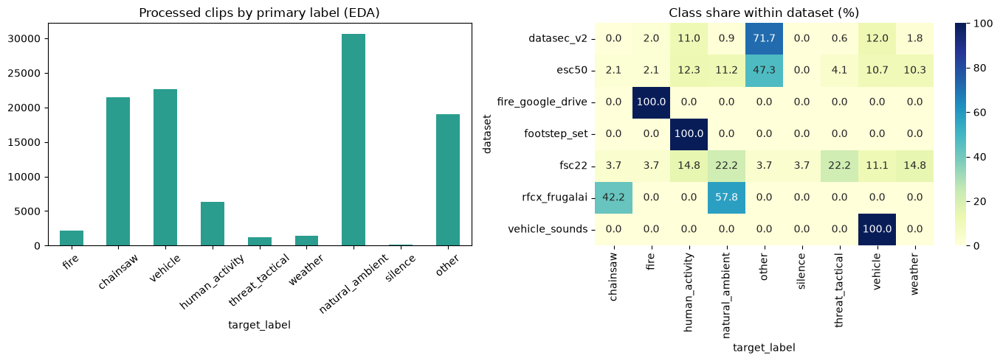

Positive clip counts by multi-label tag (each clip may count more than once):


,positive_clips
target_labels,
fire,2141
chainsaw,21499
vehicle,22619
human_activity,6344
threat_tactical,1203
weather,1433
natural_ambient,30672
silence,150
other,19044


Dataset × tag counts (multi-label):


target_labels,fire,chainsaw,vehicle,human_activity,threat_tactical,weather,natural_ambient,silence,other
dataset,,,,,,,,,
datasec_v2,470,0,2865,2620,143,433,213,0,17054
esc50,80,80,416,480,160,400,436,0,1840
fire_google_drive,1441,0,0,0,0,0,0,0,0
footstep_set,0,0,0,2644,0,0,0,0,0
fsc22,150,150,448,600,900,600,900,150,150
rfcx_frugalai,0,21269,0,0,0,0,29123,0,0
vehicle_sounds,0,0,18890,0,0,0,0,0,0


{
  "input_recordings": 71813,
  "kept_recordings": 71649,
  "excluded_recordings": 164,
  "manual_exclusions": 0,
  "exact_duplicates": 109,
  "unreadable": 0,
  "silent": 5,
  "clipping_flagged_review_only": 1119,
  "processed_clips": 105105,
  "quarantined_training_recordings": 47,
  "quarantined_training_datasets": [
    "zenodo_fire"
  ],
  "datasets": {
    "datasec_v2": 5048,
    "esc50": 2000,
    "fire_google_drive": 721,
    "footstep_set": 2127,
    "fsc22": 2025,
    "rfcx_frugalai": 50397,
    "vehicle_sounds": 9448,
    "zenodo_fire": 47
  },
  "classes": {
    "chainsaw": 21385,
    "fire": 951,
    "human_activity": 4567,
    "natural_ambient": 29886,
    "other": 3245,
    "silence": 75,
    "threat_tactical": 671,
    "vehicle": 10407,
    "weather": 626
  }
}
Reports: /Users/guidegiegg/Projects/RakForest-ML/reports
Processed manifest: /Users/guidegiegg/Projects/RakForest-ML/data/processed/processed_manifest.parquet


In [94]:
if not processed_df.empty:
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    processed_df['target_label'].value_counts().reindex(TARGET_CLASSES).dropna().plot(kind='bar',ax=axes[0],color='#2a9d8f')
    axes[0].set_title('Processed clips by primary label (EDA)'); axes[0].tick_params(axis='x',rotation=40)
    comp=pd.crosstab(processed_df.dataset,processed_df.target_label,normalize='index')*100
    sns.heatmap(comp,annot=True,fmt='.1f',cmap='YlGnBu',ax=axes[1]); axes[1].set_title('Class share within dataset (%)')
    plt.tight_layout(); plt.show()
    label_frame=processed_df[['dataset','target_labels']].copy()
    label_frame['target_labels']=label_frame.target_labels.map(json.loads)
    exploded=label_frame.explode('target_labels')
    print('Positive clip counts by multi-label tag (each clip may count more than once):')
    display(exploded.groupby('target_labels').size().reindex(TARGET_CLASSES,fill_value=0).rename('positive_clips').to_frame())
    print('Dataset × tag counts (multi-label):')
    display(pd.crosstab(exploded.dataset,exploded.target_labels).reindex(columns=TARGET_CLASSES,fill_value=0))

summary={'input_recordings':int(len(all_df)),'kept_recordings':int(len(clean_df)),'excluded_recordings':int(len(all_df)-len(clean_df)),'manual_exclusions':int(len(MANUAL_EXCLUDE_FILES)),'exact_duplicates':int(all_df.duplicate_exact.sum()),'unreadable':int(all_df.read_error.notna().sum()),'silent':int(all_df.is_silent.sum()),'clipping_flagged_review_only':int(all_df.clipping_flag.sum()),'processed_clips':int(len(processed_df)),'quarantined_training_recordings':int(quarantined_recordings),'quarantined_training_datasets':sorted(DATASETS_QUARANTINED_FROM_TRAINING),'datasets':{k:int(v) for k,v in all_df.groupby('dataset').size().items()},'classes':{k:int(v) for k,v in all_df.groupby('target_label').size().items()}}
(REPORT_DIR/'eda_cleaning_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
print(json.dumps(summary,indent=2,ensure_ascii=False))
print('Reports:',REPORT_DIR)
print('Processed manifest:',PROCESSED_DIR/'processed_manifest.parquet')


### 9.0 Post-cleaning EDA: waveform, outliers, RMS, spectral centroid และ ZCR
สุ่มตัวอย่างไม่เกิน 200 คลิปต่อ class จาก processed clips เพื่อดูคุณสมบัติหลัง preprocessing และหา outlier เบื้องต้น โดยไม่อ่านทุกคลิปซ้ำ. Outlier เป็นเพียง candidate สำหรับตรวจฟัง ไม่ถูกลบอัตโนมัติ.

Post-cleaning feature audit: 100%|██████████| 1750/1750 [00:07<00:00, 230.21it/s]


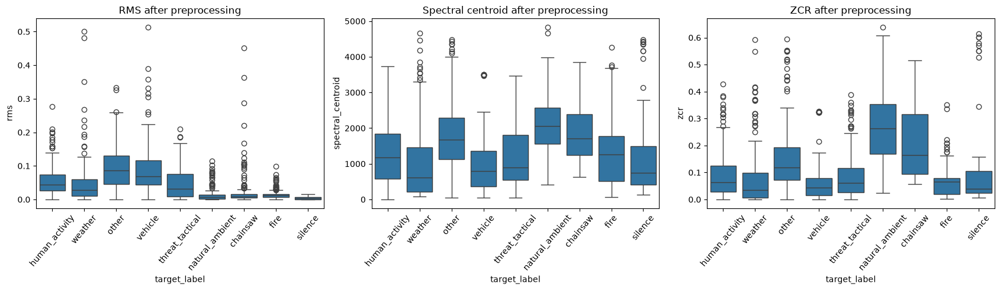

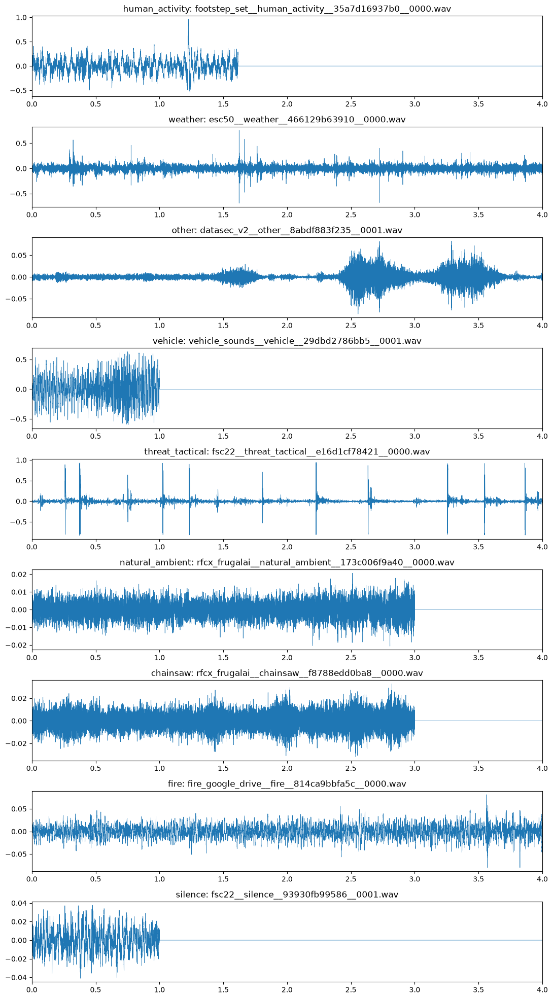

In [95]:
POST_CLEAN_MAX_PER_CLASS=200
post_sample=pd.concat([g.sample(n=min(len(g),POST_CLEAN_MAX_PER_CLASS),random_state=42) for _,g in processed_df.groupby('target_label',sort=False)],ignore_index=True) if not processed_df.empty else pd.DataFrame()
post_features=[]
for row in tqdm(post_sample.itertuples(index=False),total=len(post_sample),desc='Post-cleaning feature audit'):
    try:
        y,sr=sf.read(row.processed_file,dtype='float32')
        post_features.append({'target_label':row.target_label,'dataset':row.dataset,'processed_file':row.processed_file,'rms':float(np.sqrt(np.mean(y*y))),'spectral_centroid':float(np.mean(librosa.feature.spectral_centroid(y=y,sr=sr))),'zcr':float(np.mean(librosa.feature.zero_crossing_rate(y)))})
    except Exception: pass
post_clean_df=pd.DataFrame(post_features)
if not post_clean_df.empty: post_clean_df.to_csv(REPORT_DIR/'post_cleaning_feature_audit.csv',index=False)
if not post_clean_df.empty:
    fig,axes=plt.subplots(1,3,figsize=(17,5))
    for ax,col,title in zip(axes,['rms','spectral_centroid','zcr'],['RMS after preprocessing','Spectral centroid after preprocessing','ZCR after preprocessing']):
        sns.boxplot(data=post_clean_df,x='target_label',y=col,ax=ax); ax.set_title(title); ax.tick_params(axis='x',rotation=50)
    plt.tight_layout(); plt.show()
    # one standardized waveform example per class
    labels=list(post_clean_df.target_label.unique()); fig,axes=plt.subplots(len(labels),1,figsize=(11,2.2*len(labels))); axes=np.atleast_1d(axes)
    for ax,label in zip(axes,labels):
        path=post_clean_df.loc[post_clean_df.target_label.eq(label),'processed_file'].iloc[0]
        y,sr=sf.read(path,dtype='float32'); ax.plot(np.arange(len(y))/sr,y,lw=.5); ax.set_title(f'{label}: {Path(path).name}'); ax.set_xlim(0,TARGET_DURATION)
    plt.tight_layout(); plt.show()


### 9.0.1 Outlier audit หลัง cleaning
ตรวจ outlier ของคลิปหลัง preprocessing จากตัวอย่างไม่เกิน 200 คลิปต่อ class ที่สร้างในเซลล์ก่อนหน้า ใช้ IQR แยกภายใน class สำหรับ RMS, spectral centroid และ ZCR ตารางสรุปจะแสดงทั้งกลุ่มที่พบและไม่พบ outlier; การ flag เป็นเพียงคิวให้ตรวจฟัง ไม่ลบคลิปอัตโนมัติ.


In [96]:
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm.auto import tqdm
from IPython.display import display

# Resolve the project from the current notebook location rather than relying on stale kernel variables.
PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=='notebooks': PROJECT_ROOT=PROJECT_ROOT.parent
REPORT_DIR=PROJECT_ROOT/'reports'; REPORT_DIR.mkdir(parents=True,exist_ok=True)
feature_cache=REPORT_DIR/'post_cleaning_feature_audit.csv'
manifest_path=PROJECT_ROOT/'data'/'processed'/'processed_manifest.parquet'
MAX_PER_CLASS=200

# Reuse the feature cache only when it contains usable rows and the referenced clips still exist.
post_clean_df=pd.DataFrame()
if feature_cache.exists():
    try:
        cached=pd.read_csv(feature_cache)
        if not cached.empty and {'processed_file','rms','spectral_centroid','zcr','dataset','target_label'}.issubset(cached.columns):
            cached_paths=cached.processed_file.astype(str).map(Path)
            if cached_paths.map(Path.exists).all():
                post_clean_df=cached
                print('Loaded cached post-cleaning audio features:',feature_cache)
            else:
                print('[cache] Some clips referenced by the feature cache are missing; rebuilding the sample.')
        else:
            print('[cache] Feature cache is empty or has an old schema; rebuilding the sample.')
    except Exception as e:
        print(f'[cache] Could not read feature cache ({type(e).__name__}: {e}); rebuilding the sample.')

if post_clean_df.empty:
    if not manifest_path.exists():
        raise FileNotFoundError(f'ไม่พบ processed manifest: {manifest_path}; รัน 02 ส่วนเตรียม clips ก่อน')
    manifest=pd.read_parquet(manifest_path)
    required={'processed_file','dataset','target_label'}
    if not required.issubset(manifest.columns):
        raise ValueError(f'Manifest ขาด columns: {sorted(required-set(manifest.columns))}')
    if manifest.empty:
        raise RuntimeError(f'processed manifest ว่าง: {manifest_path}')
    # Build sampled groups with concat so pandas versions do not drop the grouping column.
    sample=pd.concat([g.sample(n=min(len(g),MAX_PER_CLASS),random_state=42) for _,g in manifest.groupby('target_label',sort=False)],ignore_index=True)
    clips_dir=PROJECT_ROOT/'data'/'processed'/'clips'
    feature_rows=[]; read_errors=[]
    for row in tqdm(sample.itertuples(index=False),total=len(sample),desc='Post-cleaning feature audit'):
        raw_path=Path(str(row.processed_file))
        candidates=[raw_path] if raw_path.is_absolute() else [PROJECT_ROOT/raw_path,raw_path]
        if not any(candidate.is_file() for candidate in candidates):
            candidates.append(clips_dir/raw_path.name)
        audio_path=next((candidate for candidate in candidates if candidate.is_file()),None)
        if audio_path is None:
            read_errors.append(f'{row.processed_file}: file not found (project root: {PROJECT_ROOT})')
            continue
        try:
            y,sr=sf.read(str(audio_path),dtype='float32')
            if y.ndim==2: y=y.mean(axis=1)
            if y.size==0: raise ValueError('empty audio')
            feature_rows.append({'target_label':row.target_label,'dataset':row.dataset,'processed_file':str(audio_path),'rms':float(np.sqrt(np.mean(y*y))),'spectral_centroid':float(np.mean(librosa.feature.spectral_centroid(y=y,sr=sr))),'zcr':float(np.mean(librosa.feature.zero_crossing_rate(y)))})
        except Exception as e:
            read_errors.append(f'{audio_path}: {type(e).__name__}: {e}')
    post_clean_df=pd.DataFrame(feature_rows)
    if post_clean_df.empty:
        preview='\n'.join(read_errors[:5]) or 'No clip paths were present in the sampled manifest.'
        raise RuntimeError(f'อ่าน processed clips ไม่สำเร็จ: ได้ {len(feature_rows)} จาก {len(sample)} คลิป\nManifest: {manifest_path}\nProject root: {PROJECT_ROOT}\nตัวอย่างสาเหตุ:\n{preview}')
    if read_errors:
        print(f'[skip] อ่านไม่ได้ {len(read_errors):,}/{len(sample):,} คลิป; ตัวอย่าง:')
        for message in read_errors[:5]: print(' -',message)
    post_clean_df.to_csv(feature_cache,index=False)
    print('Saved cached post-cleaning audio features:',feature_cache)

POST_OUTLIER_FEATURES=['rms','spectral_centroid','zcr']
for feature in POST_OUTLIER_FEATURES:
    flag=f'{feature}_outlier'
    post_clean_df[flag]=False
    for _,idx in post_clean_df.groupby('target_label').groups.items():
        values=post_clean_df.loc[idx,feature].dropna()
        if len(values)<4: continue
        q1=float(values.quantile(.25)); q3=float(values.quantile(.75)); iqr=q3-q1
        if iqr<=0: continue
        low=q1-1.5*iqr; high=q3+1.5*iqr
        post_clean_df.loc[idx,flag]=post_clean_df.loc[idx,feature].lt(low)|post_clean_df.loc[idx,feature].gt(high)
flag_cols=[f'{feature}_outlier' for feature in POST_OUTLIER_FEATURES]
post_clean_df['outlier_count']=post_clean_df[flag_cols].sum(axis=1)
post_clean_df['outlier_features']=post_clean_df.apply(lambda r:', '.join(f for f in POST_OUTLIER_FEATURES if r[f'{f}_outlier']),axis=1)
post_clean_df['outlier_any']=post_clean_df['outlier_count'].gt(0)

outlier_summary=post_clean_df.groupby(['dataset','target_label']).agg(
    sampled_clips=('processed_file','size'),
    rms_outliers=('rms_outlier','sum'),
    spectral_centroid_outliers=('spectral_centroid_outlier','sum'),
    zcr_outliers=('zcr_outlier','sum'),
    any_outliers=('outlier_any','sum')
).reset_index()
print(f'Post-cleaning outlier summary: {len(post_clean_df):,} sampled clips; max {MAX_PER_CLASS} per class')
display(outlier_summary.sort_values(['any_outliers','dataset','target_label'],ascending=[False,True,True]))

candidates=post_clean_df[post_clean_df.outlier_any].sort_values(['outlier_count','target_label'],ascending=[False,True])
if candidates.empty:
    print('ไม่พบ outlier ในตัวอย่างที่ตรวจ (ไม่ได้แปลว่าไม่มีในคลิปทั้งหมด)')
else:
    display(candidates[['dataset','target_label','processed_file','rms','spectral_centroid','zcr','outlier_features']].head(25))
    print('เปิดฟัง candidate ก่อนตัดสินใจ; ไม่มีการลบคลิปอัตโนมัติ')

summary_path=REPORT_DIR/'post_cleaning_outlier_summary.csv'
candidates_path=REPORT_DIR/'post_cleaning_outlier_candidates.csv'
outlier_summary.to_csv(summary_path,index=False)
candidates.to_csv(candidates_path,index=False)
print('Saved:',summary_path)
print('Saved:',candidates_path)


Loaded cached post-cleaning audio features: /Users/guidegiegg/Projects/RakForest-ML/reports/post_cleaning_feature_audit.csv
Post-cleaning outlier summary: 1,750 sampled clips; max 200 per class


,dataset,target_label,sampled_clips,rms_outliers,spectral_centroid_outliers,zcr_outliers,any_outliers
26,rfcx_frugalai,chainsaw,198,25,0,0,25
27,rfcx_frugalai,natural_ambient,193,19,0,0,19
0,datasec_v2,fire,51,13,0,3,16
3,datasec_v2,other,178,2,7,14,16
25,fsc22,weather,87,2,6,11,15
28,vehicle_sounds,vehicle,167,7,7,8,15
14,esc50,weather,57,8,4,7,14
23,fsc22,threat_tactical,145,1,0,12,13
16,footstep_set,human_activity,90,2,0,10,12
18,fsc22,fire,13,6,3,6,9


,dataset,target_label,processed_file,rms,spectral_centroid,zcr,outlier_features
1433,fsc22,fire,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.030995,3725.447442,0.221160,"rms, spectral_centroid, zcr"
1536,fsc22,fire,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.028778,3764.665280,0.208112,"rms, spectral_centroid, zcr"
1462,fsc22,fire,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.005737,4265.402072,0.351078,"spectral_centroid, zcr"
1541,fsc22,fire,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.030116,3685.820931,0.208124,"rms, zcr"
1135,datasec_v2,natural_ambient,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.026129,4831.019620,0.638649,"spectral_centroid, zcr"
424,datasec_v2,other,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.111574,4477.554943,0.595141,"spectral_centroid, zcr"
456,datasec_v2,other,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.127379,4367.683003,0.548014,"spectral_centroid, zcr"
476,datasec_v2,other,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.136024,4105.179545,0.518252,"spectral_centroid, zcr"
479,datasec_v2,other,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.114334,4214.196388,0.511657,"spectral_centroid, zcr"
483,datasec_v2,other,/Users/guidegiegg/Projects/RakForest-ML/data/p...,0.152274,4349.086458,0.549971,"spectral_centroid, zcr"


เปิดฟัง candidate ก่อนตัดสินใจ; ไม่มีการลบคลิปอัตโนมัติ
Saved: /Users/guidegiegg/Projects/RakForest-ML/reports/post_cleaning_outlier_summary.csv
Saved: /Users/guidegiegg/Projects/RakForest-ML/reports/post_cleaning_outlier_candidates.csv


### 9.0.2 Post-cleaning RMS envelope
เทียบค่าเฉลี่ย short-time RMS ตามเวลาในคลิปมาตรฐานต่อ class (เป็น envelope ไม่เฉลี่ย waveform ดิบ เพราะ phase ไม่ตรงกัน)


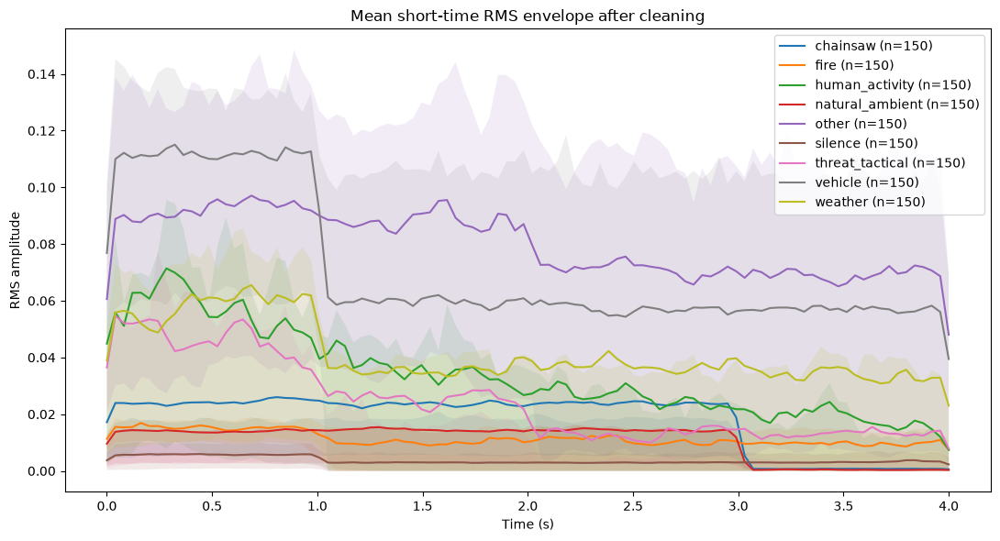

In [97]:
if not processed_df.empty:
    fig,ax=plt.subplots(figsize=(11,6))
    for label,g in processed_df.groupby('target_label'):
        sample=g.sample(min(len(g),150),random_state=42); curves=[]
        for path in sample.processed_file:
            try:
                y,sr=sf.read(path,dtype='float32'); curve=librosa.feature.rms(y=y,frame_length=1024,hop_length=320,center=True)[0]
                curves.append(np.interp(np.linspace(0,1,100),np.linspace(0,1,len(curve)),curve))
            except Exception: pass
        if curves:
            curves=np.stack(curves); x=np.linspace(0,TARGET_DURATION,curves.shape[1]); ax.plot(x,curves.mean(axis=0),label=f'{label} (n={len(curves)})'); ax.fill_between(x,np.percentile(curves,25,axis=0),np.percentile(curves,75,axis=0),alpha=.12)
    ax.set_title('Mean short-time RMS envelope after cleaning'); ax.set_xlabel('Time (s)'); ax.set_ylabel('RMS amplitude'); ax.legend(); plt.tight_layout(); plt.show()


### 9.1 Leakage check และ final comparison
ตรวจ group key ไม่ข้าม split และเปรียบเทียบ class counts ก่อน/หลัง cleaning. Leakage check ต้องได้ 0 กลุ่ม.

Groups appearing in multiple splits: 0
No group leakage detected by exact hash/source grouping.


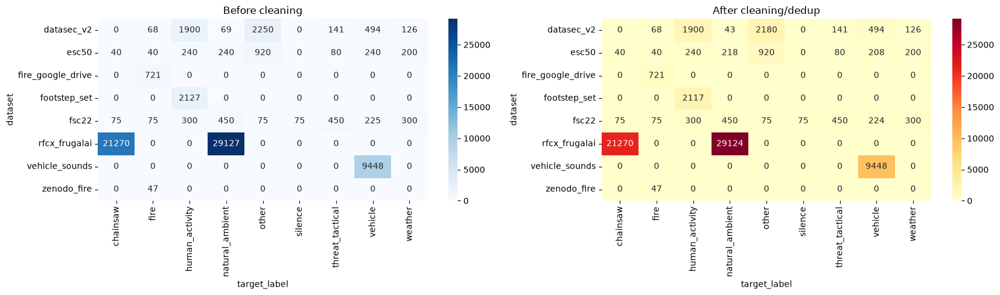

In [98]:
leak_check=clean_df.groupby('group_key')['split'].nunique()
leaked=leak_check[leak_check>1]
print('Groups appearing in multiple splits:',len(leaked))
if len(leaked): display(clean_df[clean_df.group_key.isin(leaked.index)].sort_values('group_key'))
else: print('No group leakage detected by exact hash/source grouping.')

before_counts=pd.crosstab(all_df.dataset,all_df.target_label)
after_counts=pd.crosstab(clean_df.dataset,clean_df.target_label)
all_columns=sorted(set(before_counts.columns)|set(after_counts.columns))
before_counts=before_counts.reindex(columns=all_columns,fill_value=0)
after_counts=after_counts.reindex(index=before_counts.index,columns=all_columns,fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(17,max(5,.5*len(before_counts))))
sns.heatmap(before_counts,annot=True,fmt='d',cmap='Blues',ax=axes[0]); axes[0].set_title('Before cleaning')
sns.heatmap(after_counts,annot=True,fmt='d',cmap='YlOrRd',ax=axes[1]); axes[1].set_title('After cleaning/dedup')
plt.tight_layout(); plt.show()
